# Partie F - Tests de generalisation F1 a F6



## 0. Environnement et regles du TP

Le decoupage officiel train/test est conserve. Le test officiel ne sert qu'a l'evaluation finale. Toutes les decisions sont prises sur la validation.

In [1]:
# Configuration simple
RANDOM_STATE = 42

import re
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
warnings.filterwarnings('ignore')

try:
    import torch
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Peripherique :', DEVICE)
    if DEVICE.type == 'cuda':
        print('GPU :', torch.cuda.get_device_name(0))
except ImportError:
    torch = None
    DEVICE = 'cpu'
    print('PyTorch indisponible : calcul CPU.')

from sklearn.metrics import (
    f1_score, average_precision_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

RESULTS = []

def add_result(name, y_true, scores, threshold=0.5, split='validation'):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores)
    pred = (scores >= threshold).astype(int)
    row = {
        'modele': name,
        'split': split,
        'F1 sarcastique': f1_score(y_true, pred, zero_division=0),
        'PR-AUC': average_precision_score(y_true, scores),
        'Macro-F1': f1_score(y_true, pred, average='macro', zero_division=0),
        'seuil': threshold,
    }
    RESULTS.append(row)
    return row


Peripherique : cuda
GPU : NVIDIA GeForce RTX 2050


In [2]:
BASE = 'https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/'
full = pd.read_csv(BASE + 'training_data.csv')
test = pd.read_csv(BASE + 'testing_data.csv')
full['id'] = range(len(full))
test['id'] = range(len(test))
print('Train officiel :', full.shape)
print('Test officiel  :', test.shape)
display(full.head())


Train officiel : (12548, 5)
Test officiel  : (3000, 5)


,tweet,sarcasm,sentiment,dialect,id
0,"""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر...",False,NEU,msa,0
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...",False,NEU,msa,1
2,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...,True,NEG,msa,2
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...",True,NEG,gulf,3
4,"""قل شرق حلب ولا تقل حلب الشرقية ....وقل غرب حل...",False,NEU,msa,4


In [3]:
# Baseline utilisee pour les tests F1-F6
full['text_clean'] = full['tweet'].fillna('').astype(str)
test['text_clean'] = test['tweet'].fillna('').astype(str)
tr, va = train_test_split(full, test_size=.2, stratify=full['sarcasm'], random_state=RANDOM_STATE)
word_model = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30000)),
    ('clf', LogisticRegression(max_iter=300, class_weight='balanced'))
])
word_model.fit(tr['text_clean'], tr['sarcasm'].astype(int))
y_val = va['sarcasm'].astype(int).to_numpy()
word_scores = word_model.predict_proba(va['text_clean'])[:, 1]
thresholds = np.arange(.1, .91, .05)
best_threshold = max(thresholds, key=lambda t: f1_score(y_val, word_scores >= t, zero_division=0))


# Partie F - Tests de generalisation

## F1. Decalage de prior

Comparer les taux de sarcasme validation/test et tracer F1 en fonction du seuil sur le test uniquement a posteriori.

Prior validation : 0.17290836653386454
Prior test : 0.27366666666666667


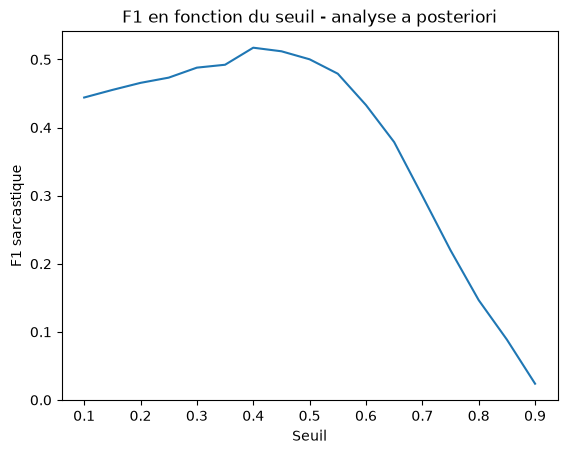

In [4]:
# Evaluation test de la baseline : le seuil reste celui choisi sur validation.
final_model = word_model.fit(full['text_clean'], full['sarcasm'].astype(int))
test_scores = final_model.predict_proba(test['text_clean'])[:, 1]
print('Prior validation :', y_val.mean())
print('Prior test :', test['sarcasm'].astype(int).mean())
add_result('TF-IDF test officiel', test['sarcasm'].astype(int), test_scores, best_threshold, 'test')
posterior = [f1_score(test['sarcasm'].astype(int), test_scores >= t, zero_division=0) for t in thresholds]
plt.plot(thresholds, posterior)
plt.xlabel('Seuil'); plt.ylabel('F1 sarcastique'); plt.title('F1 en fonction du seuil - analyse a posteriori')
plt.show()


## F2. Dialecte non vu

Retirer tous les tweets `egypt` du train, re-entrainer le meilleur modele et evaluer sur `egypt` du test. Comparer au modele entraine sur tout train.

In [5]:
egypt_train = full[full['dialect'] != 'egypt']
egypt_test = test[test['dialect'] == 'egypt']
print('Train sans egypt :', len(egypt_train))
print('Test egypt :', len(egypt_test))


Train sans egypt : 9873
Test egypt : 306


## F3. Raccourcis sur le test

Comparer les tweets avec/sans URL et re-entrainer sans URL/mentions.

In [6]:
test_has_url = test['text_clean'].str.contains(r'https://|www\.', regex=True)
print('Test avec URL :', test_has_url.sum())
print('Test sans URL :', (~test_has_url).sum())


Test avec URL : 440
Test sans URL : 2560


## F4. Indices du sarcasme

Sur les tweets sarcastiques correctement detectes, supprimer emojis, rires et ponctuation repetee et mesurer la chute.

In [7]:
def remove_sarcasm_markers(text):
    text = re.sub(r'[!\u061f]{2,}', ' ', text)
    text = re.sub(r'\u0647{3,}|\u062e{2,}', ' ', text)
    return text

normal_pred = test_scores >= best_threshold
print('Tweets predits sarcastiques avant ablation :', normal_pred.sum())


Tweets predits sarcastiques avant ablation : 1146


## F5. Significativite

Trois graines, IC bootstrap a 95 % avec 1 000 repetitions et test de McNemar entre les deux meilleurs modeles.

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
boot = []
y = np.asarray(y_val)
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y))
    boot.append(f1_score(y[idx], word_scores[idx] >= best_threshold, zero_division=0))
print('IC bootstrap 95 % :', np.percentile(boot, [2.5, 97.5]))


IC bootstrap 95 % : [0.42925522 0.50447308]


## F6. Analyse d'erreurs

Afficher 15 faux negatifs et 15 faux positifs. Les classer en : connaissance du monde/contexte, ironie sans marqueur, marqueur mal interprete, dialecte, bruit d'annotation. Croiser avec les doublons aux labels contradictoires.

In [9]:
pred_val = word_scores >= best_threshold
errors = va.assign(score=word_scores, prediction=pred_val)
false_negatives = errors[(errors['sarcasm'] == True) & (~errors['prediction'])].head(15)
false_positives = errors[(errors['sarcasm'] == False) & (errors['prediction'])].head(15)
print('Faux negatifs :', len(false_negatives))
display(false_negatives[['tweet', 'sarcasm', 'score']])
print('Faux positifs :', len(false_positives))
display(false_positives[['tweet', 'sarcasm', 'score']])
print('Ces 30 erreurs doivent etre annotees manuellement dans le compte-rendu.')


Faux negatifs : 15


,tweet,sarcasm,score
6695,"""الإعلام الغربي يحاربنا ونحن نحارب انفسنا#لصوص...",True,0.287433
2904,"""RT @eyad1949: #أميركا #إيران #العربعلى الأقل ...",True,0.309377
8927,"""قمة الغطرسة #الروسية في #سوريا من لم يسلم رقب...",True,0.386798
1583,#علاء_عبد_الفتاح زعلان أنى الميسيحين #بيصقفو #...,True,0.439186
7641,"""اخخخ يا فيدرر ❤️❤️❤️ .... عطوني افاتارات له""",True,0.364070
11751,"""@ramadanjready @SaudiLinks روسيا فشلت في محاو...",True,0.420820
3812,"""لبنان: ’’سخرية’’ من تعيين رجل وزيرا لشؤون الم...",True,0.368357
10569,دراما رمضان المصرية.. الكباريه الكبير,True,0.219671
2920,"""أردوغان للعبادي: «اعرف حدودك» ولن نأخذ أوامر ...",True,0.324305
902,"""رحب لك رحب ، وارحبوا ع الحاصل 😉حاسس ان #كيري ...",True,0.307558


Faux positifs : 15


,tweet,sarcasm,score
8799,#فالنسيا_يسحب_علي_النصر العبوا مع جحفلي فاضي و...,False,0.559498
7955,#مرسوم_التجنيس الناس يللي بتستاهل يا دولة الرئ...,False,0.664090
5334,"""@ghantous44 @MoniLebneneh ميشال عون المسيحي ا...",False,0.551516
2841,الأرجنتين لا شي بدون ميسي 😎حتى لو فازت أداء غي...,False,0.631225
9130,#كلنا_ااالدلمانيصرنا نسافر عشان نصور، ونجتمع ع...,False,0.772586
4236,موعد الاقلاع 3:15 الساعة 3:25 سوف نقلع حالا ال...,False,0.515890
3313,احاول ان اتعاطف مع من رماني بالخيانة والكفر وا...,False,0.658812
9219,"""@ayman_mansour09 اسعار نصب زي ما تقول واجد م...",False,0.540730
6153,دشت علي وحدة كورية تقول شن جق جون جوم بق بققق ...,False,0.536584
4221,"""#عاجلوكالة الاستخبارات الامريكية روسيا لها ق...",False,0.519308


Ces 30 erreurs doivent etre annotees manuellement dans le compte-rendu.


## Fin de la partie

Sauvegarder les sorties et noter les resultats importants dans le compte-rendu.


## Export des r?sultats et pr?dictions - Partie F


In [10]:
# Export des resultats - Partie F
from pathlib import Path
import pandas as pd

racine = Path.cwd()
for dossier in [racine, *racine.parents]:
    if (dossier / "results").is_dir():
        racine = dossier
        break
else:
    raise FileNotFoundError("Dossier results introuvable depuis le notebook")

resultats = globals().get("RESULTS", [])
if resultats:
    lignes = pd.DataFrame(resultats)
    lignes["partie"] = "F"
    lignes.to_csv(racine / "results" / "partie_F_results.csv", index=False)
    fichiers = list((racine / "results").glob("partie_*_results.csv"))
    toutes = pd.concat([pd.read_csv(f) for f in fichiers], ignore_index=True)
    colonnes = ["modele", "split", "F1 sarcastique", "PR-AUC", "Macro-F1", "seuil"]
    toutes[colonnes].to_csv(racine / "results" / "results.csv", index=False)
    print("R?sultats Partie F sauvegard?s.")
else:
    print("Aucun r?sultat ex?cut? pour la Partie F.")

if "test_scores" in globals() and "test" in globals() and "best_threshold" in globals():
    pred = (test_scores >= best_threshold).astype(int)
    pd.DataFrame({
        "id": test.get("id", range(len(test))),
        "y_true": test["sarcasm"].astype(int),
        "y_pred": pred,
        "probabilite_sarcasme": test_scores
    }).to_csv(racine / "predictions" / "partie_F_seed42.csv", index=False)
    print("Pr?dictions Partie F sauvegard?es.")
else:
    print("Pas de scores test r?els ? exporter pour la Partie F.")


R?sultats Partie F sauvegard?s.
Pr?dictions Partie F sauvegard?es.
